In [1]:
# Necessary libraries to import

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# Load the csv data

# df = pd.read_csv('/Users/ahmed/Desktop/CDUT-OBU Classes/CHC6089 Machine Learning-Ahmed/Week 1/chronic_kidney_disease.csv')
df = pd.read_csv('chronic_kidney_disease.csv')

In [3]:
# to drop/remove any attribute eg 'id' that is not important use df.drop()
df.drop('id', axis = 1, inplace = True)

In [4]:
# As we can see that some attributes values such as 'packed_cell_volume', 'white_blood_cell_count' and 'red_blood_cell_count' are object type. 
# We need to change them to numerical dtype.

# converting necessary columns in object type to numerical type

df['pcv'] = pd.to_numeric(df['pcv'], errors='coerce')
df['wc'] = pd.to_numeric(df['wc'], errors='coerce')
df['rc'] = pd.to_numeric(df['rc'], errors='coerce')

In [5]:
# Extracting categorical and numerical columns

cat_cols = [col for col in df.columns if df[col].dtype == 'object']
num_cols = [col for col in df.columns if df[col].dtype != 'object']

In [6]:
# looking at unique values in categorical columns

for col in cat_cols:
    print(f"{col} has {df[col].unique()} values\n")

In [7]:
df['dm'] = df['dm'].replace({'\tno': 'no','\tyes': 'yes',' yes': 'yes'})

# Fix the 'cad' column
df['cad'] = df['cad'].replace({'\tno': 'no'})

# Fix the 'classification' column
df['classification'] = df['classification'].replace({'ckd\t': 'ckd','notckd': 'not ckd'})

# Display the cleaned data
print(df[['dm', 'cad', 'classification']].head())

    dm cad classification
0  yes  no            ckd
1   no  no            ckd
2  yes  no            ckd
3   no  no            ckd
4   no  no            ckd


In [8]:
# print the columns belwo to see their current values
cols = ['dm', 'cad', 'classification']

for col in cols:
    print(f"{col} has {df[col].unique()} values\n")

dm has <StringArray>
['yes', 'no', nan]
Length: 3, dtype: str values

cad has <StringArray>
['no', 'yes', nan]
Length: 3, dtype: str values

classification has <StringArray>
['ckd', 'not ckd']
Length: 2, dtype: str values



In [9]:
from sklearn.model_selection import train_test_split

# Convert classification labels to 0 and 1
df["classification"] = df["classification"].map({
    "ckd": 1,
    "not ckd": 0
})

# Separate features and target
x = df.drop(columns=["classification"])
y = df["classification"]

# Split the dataset: 80% training, 20% testing
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data: (320, 24)
Testing data: (80, 24)

Training class distribution:
classification
1    200
0    120
Name: count, dtype: int64

Testing class distribution:
classification
1    50
0    30
Name: count, dtype: int64


In [10]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical features
num_cols = [
    'age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu',
    'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc'
]

# Categorical features
cat_cols = [
    'rbc', 'pc', 'pcc', 'ba', 'htn',
    'dm', 'cad', 'appet', 'pe', 'ane'
]

# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Missing'
    )),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# How to get any algorithm's parameters

In [11]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
print(model.get_params())

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': None, 'verbose': 0, 'warm_start': False}


# Logistic Regression with GridSearchCV

## When we use GridSearchCV directly on an algorithm, we write the parameter name. 
## When the algorithm is inside a pipeline, we add its pipeline step name followed by two underscores

In [12]:
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import make_pipeline
from imblearn.over_sampling import SVMSMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Define the model
lr_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    LogisticRegression(max_iter=1000)
)

# Define the hyperparameter grid
param_grid = {
    'logisticregression__C': [0.1, 1, 10, 100],
    'logisticregression__solver': ['lbfgs', 'liblinear']
}

# Apply GridSearchCV
search_lr = GridSearchCV(
    lr_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_lr.fit(x_train, y_train)

# Make predictions using the best model
y_pred_lr_tuned = search_lr.predict(x_test)

# Display results
print("Best Parameters:", search_lr.best_params_)
print("Validation Accuracy:", search_lr.best_score_)
print("Tuned LR Accuracy:",
      accuracy_score(y_test, y_pred_lr_tuned))

Best Parameters: {'logisticregression__C': 10, 'logisticregression__solver': 'lbfgs'}
Validation Accuracy: 0.996875
Tuned LR Accuracy: 0.975


# SVM with GridSearchCV

In [13]:
from sklearn.svm import SVC

# Define the SVM model
svm_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    SVC()
)

# Define the hyperparameter grid
param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__kernel': ['linear', 'rbf']
}

# Apply GridSearchCV
search_svm = GridSearchCV(
    svm_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_svm.fit(x_train, y_train)

# Make predictions using the best model
y_pred_svm_tuned = search_svm.predict(x_test)

# Display results
print("Best Parameters:", search_svm.best_params_)
print("Validation Accuracy:", search_svm.best_score_)
print("Tuned SVM Accuracy:",
      accuracy_score(y_test, y_pred_svm_tuned))

Best Parameters: {'svc__C': 0.1, 'svc__kernel': 'linear'}
Validation Accuracy: 0.996875
Tuned SVM Accuracy: 0.975


# KNN with GridSearchCV

In [14]:
from sklearn.neighbors import KNeighborsClassifier

# Define the KNN model
knn_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    KNeighborsClassifier()
)

# Define the hyperparameter grid
param_grid = {
    'kneighborsclassifier__n_neighbors': [3, 5, 7],
    'kneighborsclassifier__weights': ['uniform', 'distance']
}

# Apply GridSearchCV
search_knn = GridSearchCV(
    knn_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_knn.fit(x_train, y_train)

# Make predictions using the best model
y_pred_knn_tuned = search_knn.predict(x_test)

# Display results
print("Best Parameters:", search_knn.best_params_)
print("Validation Accuracy:", search_knn.best_score_)
print("Tuned KNN Accuracy:",
      accuracy_score(y_test, y_pred_knn_tuned))

Best Parameters: {'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'uniform'}
Validation Accuracy: 0.978125
Tuned KNN Accuracy: 0.9875


# Decision Tree with GridSearchCV

In [15]:
from sklearn.tree import DecisionTreeClassifier

# Define the Decision Tree model
dt_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    DecisionTreeClassifier()
)

# Define the hyperparameter grid
param_grid = {
    'decisiontreeclassifier__max_depth': [3, 5, 7],
    'decisiontreeclassifier__criterion': ['gini', 'entropy']
}

# Apply GridSearchCV
search_dt = GridSearchCV(
    dt_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_dt.fit(x_train, y_train)

# Make predictions using the best model
y_pred_dt_tuned = search_dt.predict(x_test)

# Display results
print("Best Parameters:", search_dt.best_params_)
print("Validation Accuracy:", search_dt.best_score_)
print("Tuned Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt_tuned))

Best Parameters: {'decisiontreeclassifier__criterion': 'entropy', 'decisiontreeclassifier__max_depth': 5}
Validation Accuracy: 0.990625
Tuned Decision Tree Accuracy: 0.9625


# Random Forest with GridSearchCV

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Define the Random Forest model
rf_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    RandomForestClassifier(random_state=42)
)

# Define the hyperparameter grid
param_grid = {
    'randomforestclassifier__n_estimators': [50, 100, 200],
    'randomforestclassifier__max_depth': [5, 10, 15]
}

# Apply GridSearchCV
search_rf = GridSearchCV(
    rf_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_rf.fit(x_train, y_train)

# Make predictions using the best model
y_pred_rf_tuned = search_rf.predict(x_test)

# Display results
print("Best Parameters:", search_rf.best_params_)
print("Validation Accuracy:", search_rf.best_score_)
print("Tuned Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf_tuned))

Best Parameters: {'randomforestclassifier__max_depth': 5, 'randomforestclassifier__n_estimators': 100}
Validation Accuracy: 0.99375
Tuned Random Forest Accuracy: 1.0


# AdaBoost with GridSearchCV

In [17]:
from sklearn.ensemble import AdaBoostClassifier

# Define the AdaBoost model
# We use SAMME in AdaBoost because the older SAMME.R algorithm is deprecated in our scikit-learn version
# SAMME combines several weak classifiers to build a stronger model and avoids the deprecation warnings
ada_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    AdaBoostClassifier(
        # algorithm='SAMME',
        random_state=42
    )
)

# Define the hyperparameter grid
param_grid = {
    'adaboostclassifier__n_estimators': [50, 100, 200],
    'adaboostclassifier__learning_rate': [0.01, 0.1, 1.0]
}

# Apply GridSearchCV
search_ada = GridSearchCV(
    ada_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_ada.fit(x_train, y_train)

# Make predictions using the best model
y_pred_ada_tuned = search_ada.predict(x_test)

# Display results
print("Best Parameters:", search_ada.best_params_)
print("Validation Accuracy:", search_ada.best_score_)
print("Tuned AdaBoost Accuracy:",
      accuracy_score(y_test, y_pred_ada_tuned))

Best Parameters: {'adaboostclassifier__learning_rate': 1.0, 'adaboostclassifier__n_estimators': 100}
Validation Accuracy: 0.996875
Tuned AdaBoost Accuracy: 0.9875


# Stacking with GridSearchCV

In [18]:
from sklearn.ensemble import StackingClassifier

# Define the base classifiers
base_models = [
    ('lr', LogisticRegression(max_iter=1000)),
    ('svm', SVC()),
    ('dt', DecisionTreeClassifier(random_state=42))
]

# Define the Stacking model
stack_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    StackingClassifier(
        estimators=base_models,
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5
    )
)

# Define the hyperparameter grid
param_grid = {
    'stackingclassifier__final_estimator__C': [0.1, 1, 10],
    'stackingclassifier__dt__max_depth': [3, 5]
}

# Apply GridSearchCV
search_stack = GridSearchCV(
    stack_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_stack.fit(x_train, y_train)

# Make predictions using the best model
y_pred_stack_tuned = search_stack.predict(x_test)

# Display results
print("Best Parameters:", search_stack.best_params_)
print("Validation Accuracy:", search_stack.best_score_)
print("Tuned Stacking Accuracy:",
      accuracy_score(y_test, y_pred_stack_tuned))

Best Parameters: {'stackingclassifier__dt__max_depth': 3, 'stackingclassifier__final_estimator__C': 0.1}
Validation Accuracy: 0.996875
Tuned Stacking Accuracy: 1.0


# Voting Classifier with GridSearchCV

In [19]:
from sklearn.ensemble import VotingClassifier
from sklearn.calibration import CalibratedClassifierCV

# Define the base classifiers
base_models = [
    ('lr', LogisticRegression(max_iter=1000)),
    # ('svm', SVC(probability=True)),
    ('svm', CalibratedClassifierCV(SVC(), ensemble=False)),
    ('dt', DecisionTreeClassifier(random_state=42))
]

# Define the Voting Classifier
voting_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    VotingClassifier(
        estimators=base_models,
        voting='soft'
    )
)

# Define the hyperparameter grid
param_grid = {
    'votingclassifier__lr__C': [0.1, 1, 10],
    # 'votingclassifier__svm__C': [0.1, 1, 10]
    'votingclassifier__svm__estimator__C': [0.1, 1, 10]
}

# Apply GridSearchCV
search_voting = GridSearchCV(
    voting_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_voting.fit(x_train, y_train)

# Make predictions using the best model
y_pred_voting_tuned = search_voting.predict(x_test)

# Display results
print("Best Parameters:", search_voting.best_params_)
print("Validation Accuracy:", search_voting.best_score_)
print("Tuned Voting Accuracy:",
      accuracy_score(y_test, y_pred_voting_tuned))

Best Parameters: {'votingclassifier__lr__C': 0.1, 'votingclassifier__svm__estimator__C': 1}
Validation Accuracy: 0.996875
Tuned Voting Accuracy: 1.0


# LightGBM with GridSearchCV

In [20]:
from lightgbm import LGBMClassifier

# Define the LightGBM model
lgbm_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    LGBMClassifier(random_state=42, verbosity=-1)
)

# Define the hyperparameter grid
param_grid = {
    'lgbmclassifier__n_estimators': [50, 100, 200],
    'lgbmclassifier__learning_rate': [0.01, 0.1, 0.2]
}

# Apply GridSearchCV
search_lgbm = GridSearchCV(
    lgbm_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_lgbm.fit(x_train, y_train)

# Make predictions using the best model
y_pred_lgbm_tuned = search_lgbm.predict(x_test)

# Display results
print("Best Parameters:", search_lgbm.best_params_)
print("Validation Accuracy:", search_lgbm.best_score_)
print("Tuned LightGBM Accuracy:",
      accuracy_score(y_test, y_pred_lgbm_tuned))

Best Parameters: {'lgbmclassifier__learning_rate': 0.1, 'lgbmclassifier__n_estimators': 50}
Validation Accuracy: 0.996875
Tuned LightGBM Accuracy: 1.0


# LightGBM with GridSearchCV

In [21]:
from lightgbm import LGBMClassifier

# Define the LightGBM model
lgbm_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    LGBMClassifier(random_state=42, verbosity=-1)
)

# Define the hyperparameter grid
param_grid = {
    'lgbmclassifier__n_estimators': [50, 100, 200],
    'lgbmclassifier__learning_rate': [0.01, 0.1, 0.2]
}

# Apply GridSearchCV
search_lgbm = GridSearchCV(
    lgbm_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_lgbm.fit(x_train, y_train)

# Make predictions using the best model
y_pred_lgbm_tuned = search_lgbm.predict(x_test)

# Display results
print("Best Parameters:", search_lgbm.best_params_)
print("Validation Accuracy:", search_lgbm.best_score_)
print("Tuned LightGBM Accuracy:",
      accuracy_score(y_test, y_pred_lgbm_tuned))

Best Parameters: {'lgbmclassifier__learning_rate': 0.1, 'lgbmclassifier__n_estimators': 50}
Validation Accuracy: 0.996875
Tuned LightGBM Accuracy: 1.0


# CatBoost with GridSearchCV

In [22]:
from catboost import CatBoostClassifier

# Define the CatBoost model
cat_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    CatBoostClassifier(random_seed=42, verbose=0)
)

# Define the hyperparameter grid
param_grid = {
    'catboostclassifier__iterations': [50, 100, 200],
    'catboostclassifier__depth': [4, 6],
    'catboostclassifier__learning_rate': [0.01, 0.1]
}

# Apply GridSearchCV
search_cat = GridSearchCV(
    cat_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_cat.fit(x_train, y_train)

# Make predictions using the best model
y_pred_cat_tuned = search_cat.predict(x_test)

# Display results
print("Best Parameters:", search_cat.best_params_)
print("Validation Accuracy:", search_cat.best_score_)
print("Tuned CatBoost Accuracy:",
      accuracy_score(y_test, y_pred_cat_tuned))

Best Parameters: {'catboostclassifier__depth': 4, 'catboostclassifier__iterations': 50, 'catboostclassifier__learning_rate': 0.1}
Validation Accuracy: 0.996875
Tuned CatBoost Accuracy: 1.0


# XGBoost with GridSearchCV

In [23]:
from xgboost import XGBClassifier

# Define the XGBoost model
xgb_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0)
)

# Define the hyperparameter grid
param_grid = {
    'xgbclassifier__n_estimators': [50, 100, 200],
    'xgbclassifier__max_depth': [3, 5],
    'xgbclassifier__learning_rate': [0.01, 0.1]
}

# Apply GridSearchCV
search_xgb = GridSearchCV(
    xgb_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_xgb.fit(x_train, y_train)

# Make predictions using the best model
y_pred_xgb_tuned = search_xgb.predict(x_test)

# Display results
print("Best Parameters:", search_xgb.best_params_)
print("Validation Accuracy:", search_xgb.best_score_)
print("Tuned XGBoost Accuracy:",
      accuracy_score(y_test, y_pred_xgb_tuned))

Best Parameters: {'xgbclassifier__learning_rate': 0.1, 'xgbclassifier__max_depth': 5, 'xgbclassifier__n_estimators': 50}
Validation Accuracy: 0.99375
Tuned XGBoost Accuracy: 1.0


# Bagging Classifier with GridSearchCV

In [24]:
from sklearn.ensemble import BaggingClassifier

# Define the Bagging model
bag_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    BaggingClassifier(random_state=42)
)

# Define the hyperparameter grid
param_grid = {
    'baggingclassifier__n_estimators': [10, 50, 100],
    'baggingclassifier__max_samples': [0.7, 1.0]
}

# Apply GridSearchCV
search_bag = GridSearchCV(
    bag_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_bag.fit(x_train, y_train)

# Make predictions using the best model
y_pred_bag_tuned = search_bag.predict(x_test)

# Display results
print("Best Parameters:", search_bag.best_params_)
print("Validation Accuracy:", search_bag.best_score_)
print("Tuned Bagging Accuracy:",
      accuracy_score(y_test, y_pred_bag_tuned))

Best Parameters: {'baggingclassifier__max_samples': 1.0, 'baggingclassifier__n_estimators': 10}
Validation Accuracy: 0.984375
Tuned Bagging Accuracy: 0.9875


# Gradient Boosting (GBDT) with GridSearchCV

In [25]:
from sklearn.ensemble import GradientBoostingClassifier

# Define the Gradient Boosting model
gb_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    GradientBoostingClassifier(random_state=42)
)

# Define the hyperparameter grid
param_grid = {
    'gradientboostingclassifier__n_estimators': [50, 100, 200],
    'gradientboostingclassifier__learning_rate': [0.01, 0.1, 0.2]
}

# Apply GridSearchCV
search_gb = GridSearchCV(
    gb_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_gb.fit(x_train, y_train)

# Make predictions using the best model
y_pred_gb_tuned = search_gb.predict(x_test)

# Display results
print("Best Parameters:", search_gb.best_params_)
print("Validation Accuracy:", search_gb.best_score_)
print("Tuned Gradient Boosting Accuracy:",
      accuracy_score(y_test, y_pred_gb_tuned))

Best Parameters: {'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__n_estimators': 100}
Validation Accuracy: 0.99375
Tuned Gradient Boosting Accuracy: 1.0


# Extra Trees Classifier with GridSearchCV

In [26]:
from sklearn.ensemble import ExtraTreesClassifier

# Define the Extra Trees model
et_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    ExtraTreesClassifier(random_state=42)
)

# Define the hyperparameter grid
param_grid = {
    'extratreesclassifier__n_estimators': [50, 100, 200],
    'extratreesclassifier__max_depth': [5, 10, None]
}

# Apply GridSearchCV
search_et = GridSearchCV(
    et_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_et.fit(x_train, y_train)

# Make predictions using the best model
y_pred_et_tuned = search_et.predict(x_test)

# Display results
print("Best Parameters:", search_et.best_params_)
print("Validation Accuracy:", search_et.best_score_)
print("Tuned Extra Trees Accuracy:",
      accuracy_score(y_test, y_pred_et_tuned))

Best Parameters: {'extratreesclassifier__max_depth': 10, 'extratreesclassifier__n_estimators': 50}
Validation Accuracy: 1.0
Tuned Extra Trees Accuracy: 1.0


# Gaussian Naive Bayes (GNB) with GridSearchCV

In [27]:
from sklearn.naive_bayes import GaussianNB

# Define the Gaussian Naive Bayes model
gnb_tuned = make_pipeline(
    preprocessor,
    SVMSMOTE(random_state=42),
    GaussianNB()
)

# Define the hyperparameter grid
param_grid = {
    'gaussiannb__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]
}

# Apply GridSearchCV
search_gnb = GridSearchCV(
    gnb_tuned,
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Train the model
search_gnb.fit(x_train, y_train)

# Make predictions using the best model
y_pred_gnb_tuned = search_gnb.predict(x_test)

# Display results
print("Best Parameters:", search_gnb.best_params_)
print("Validation Accuracy:", search_gnb.best_score_)
print("Tuned GNB Accuracy:",
      accuracy_score(y_test, y_pred_gnb_tuned))

Best Parameters: {'gaussiannb__var_smoothing': 1e-07}
Validation Accuracy: 0.95
Tuned GNB Accuracy: 0.95


# Compare all 15 classifiers

In [28]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score
)
import pandas as pd

results = []

# Store all 15 trained GridSearchCV models

models = {
    'Logistic Regression': search_lr,
    'SVM': search_svm,
    'Decision Tree': search_dt,
    'Random Forest': search_rf,
    'AdaBoost': search_ada,
    'Gradient Boosting': search_gb,
    'KNN': search_knn,
    'Stacking': search_stack,
    'Voting': search_voting,
    'LightGBM': search_lgbm,
    'CatBoost': search_cat,
    'XGBoost': search_xgb,
    'Bagging': search_bag,
    'Extra Trees': search_et,
    'Gaussian NB': search_gnb
}

for name, model in models.items():

    # Make predictions
    y_pred = model.predict(x_test)

    # Get scores for ROC-AUC
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(x_test)[:, 1]
    else:
        y_score = model.decision_function(x_test)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Store results
    results.append({
        'Algorithm': name,
        'Validation Accuracy': model.best_score_,
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'Specificity': tn / (tn + fp),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_score)
    })

# Create comparison table
results_df = pd.DataFrame(results)

# Sort by validation accuracy
results_df = results_df.sort_values(
    by='Validation Accuracy',
    ascending=False
)

display(results_df.round(4))

,Algorithm,Validation Accuracy,Test Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC
13,Extra Trees,1.0000,1.0000,1.0,1.00,1.0,1.0000,1.0000
1,SVM,0.9969,0.9750,1.0,0.96,1.0,0.9796,0.9847
0,Logistic Regression,0.9969,0.9750,1.0,0.96,1.0,0.9796,0.9787
8,Voting,0.9969,1.0000,1.0,1.00,1.0,1.0000,1.0000
9,LightGBM,0.9969,1.0000,1.0,1.00,1.0,1.0000,1.0000
7,Stacking,0.9969,1.0000,1.0,1.00,1.0,1.0000,1.0000
4,AdaBoost,0.9969,0.9875,1.0,0.98,1.0,0.9899,1.0000
10,CatBoost,0.9969,1.0000,1.0,1.00,1.0,1.0000,1.0000
11,XGBoost,0.9938,1.0000,1.0,1.00,1.0,1.0000,1.0000
3,Random Forest,0.9938,1.0000,1.0,1.00,1.0,1.0000,1.0000


# Learning curves for all 15 classifiers

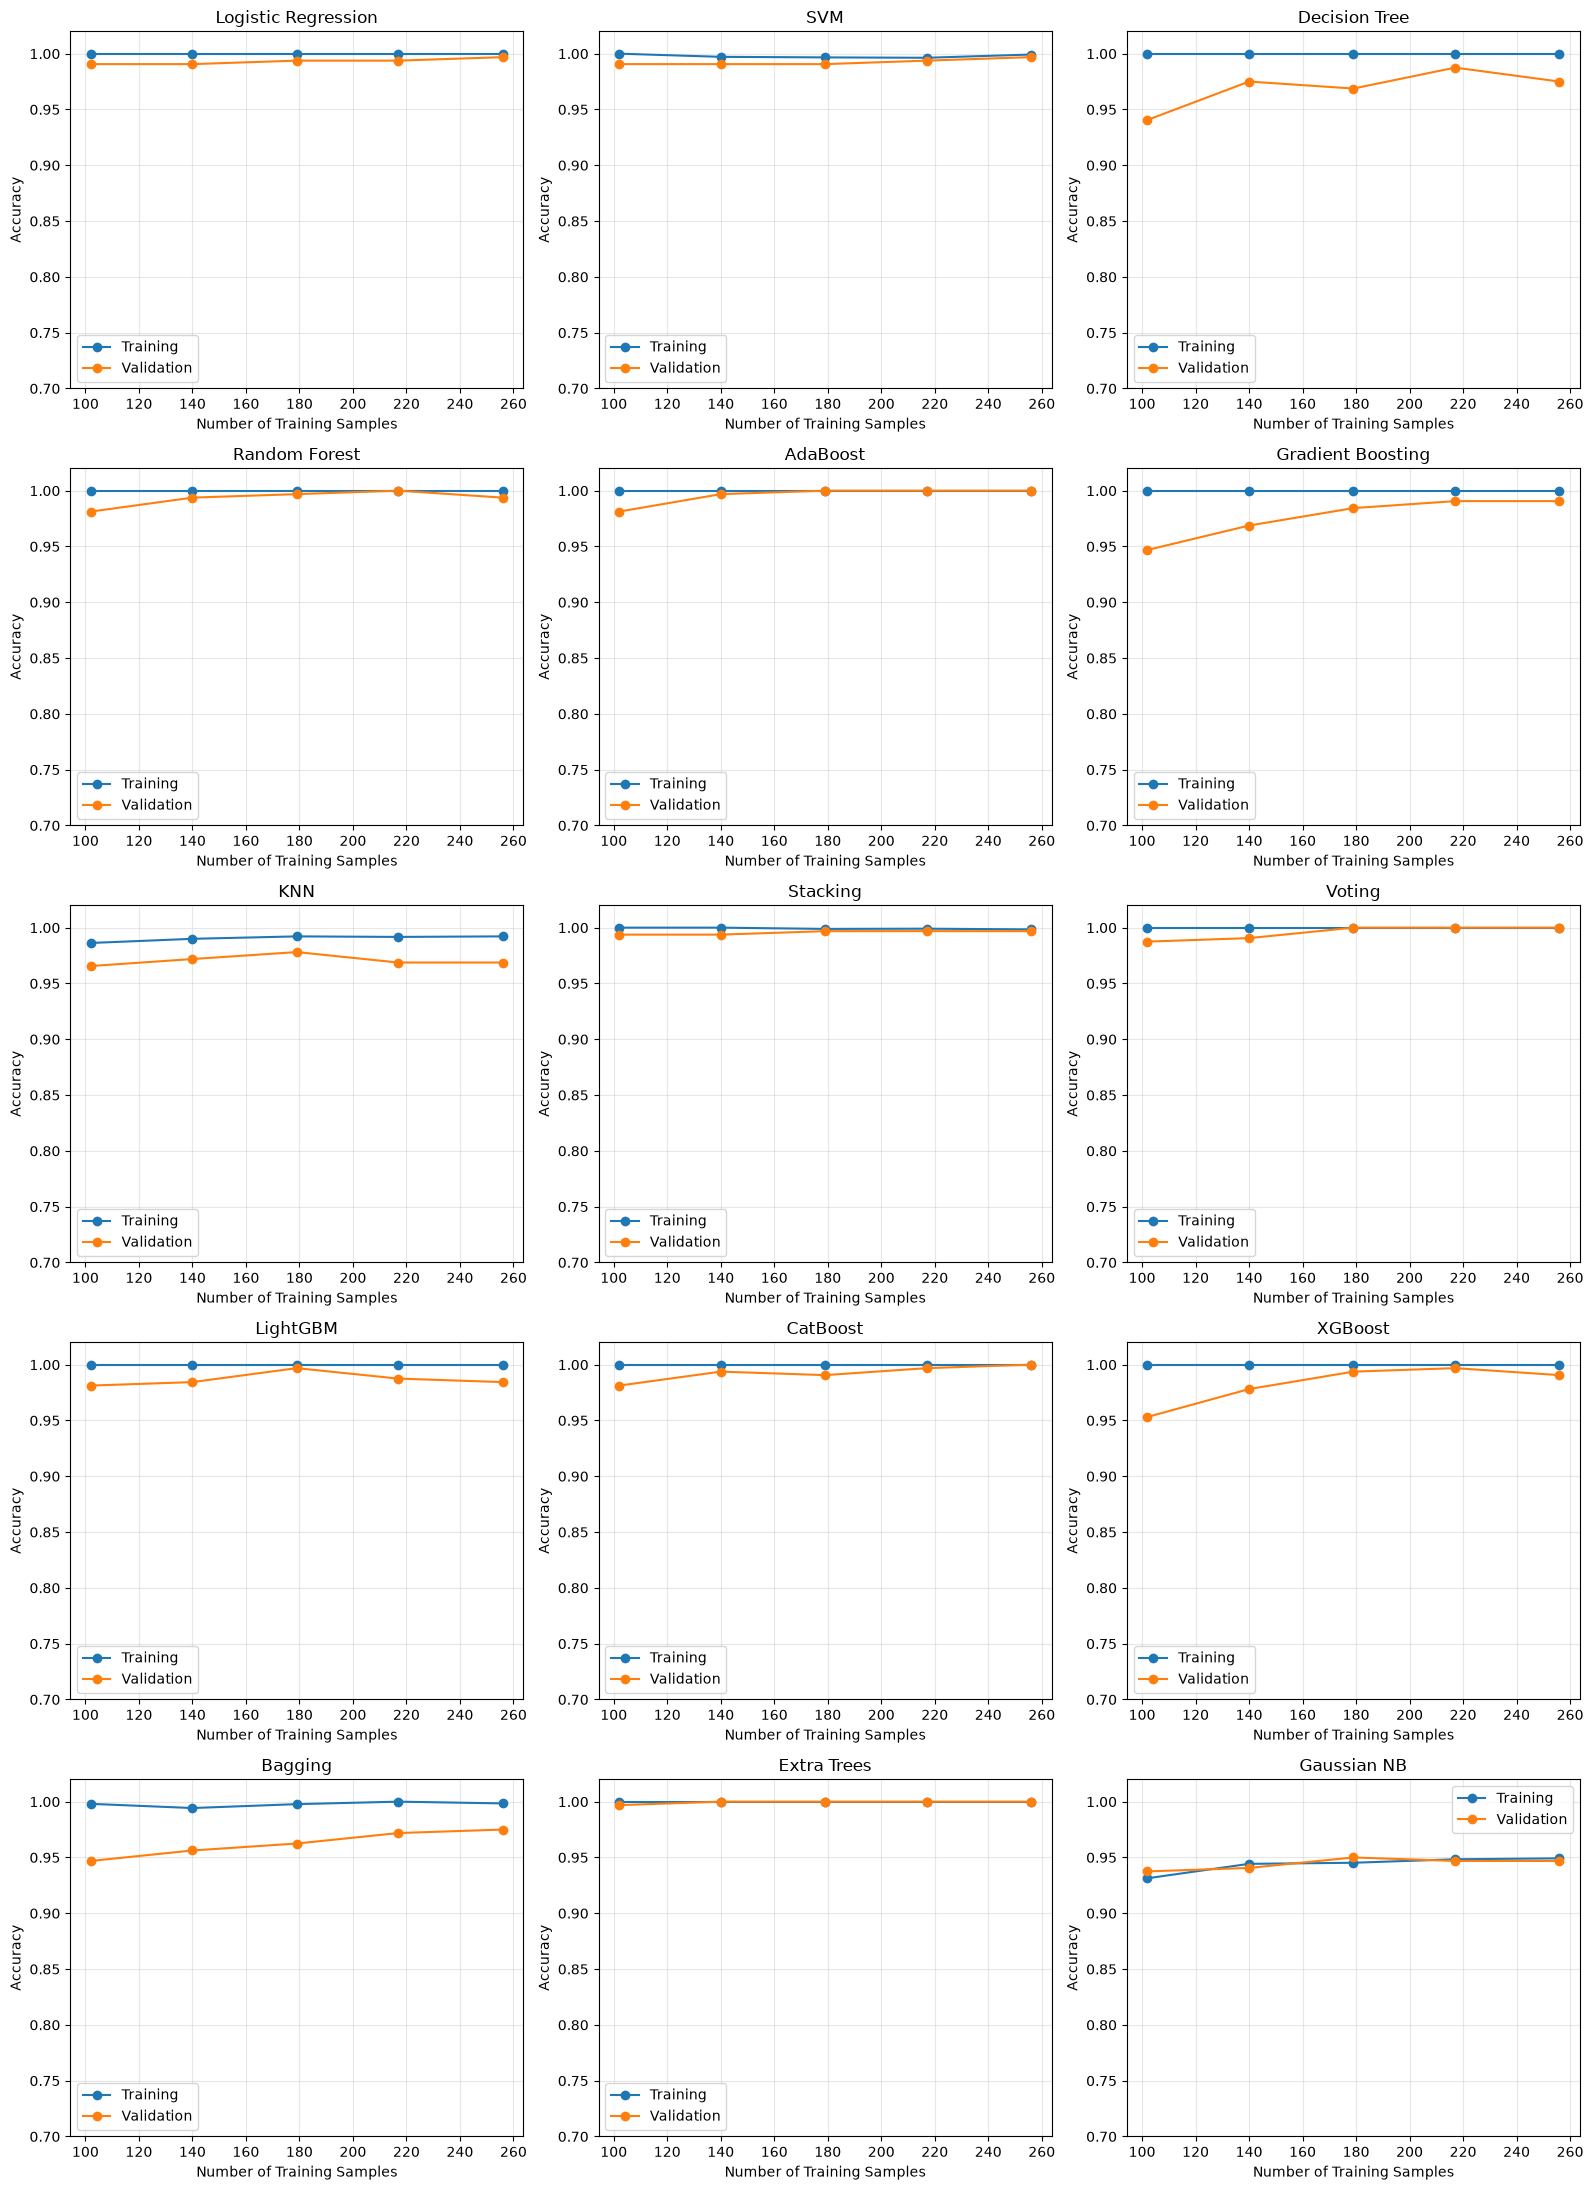

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedKFold

# Define cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Create 15 subplots
fig, axes = plt.subplots(5, 3, figsize=(16, 22))

for ax, (name, search) in zip(axes.flat, models.items()):

    # Use the best model found by GridSearchCV
    best_model = search.best_estimator_

    # Calculate learning curve
    train_sizes, train_scores, val_scores = learning_curve(
        best_model,
        x_train,
        y_train,
        cv=cv,
        train_sizes=np.linspace(0.4, 1.0, 5),
        scoring='accuracy',
        shuffle=True,
        random_state=42,
        n_jobs=1
    )

    # Calculate average accuracy
    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)

    # Plot learning curves
    ax.plot(train_sizes, train_mean, 'o-', label='Training')
    ax.plot(train_sizes, val_mean, 'o-', label='Validation')

    ax.set_title(name)
    ax.set_xlabel('Number of Training Samples')
    ax.set_ylabel('Accuracy')
    ax.set_ylim(0.7, 1.02)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# Feature Selection with GridSearchCV

# Logistic Regression with Lasso Feature Selection + GridSearchCV

In [30]:

from sklearn.linear_model import Lasso, LogisticRegression
from sklearn.feature_selection import SelectFromModel
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score,
    classification_report
)

# Step 1: Lasso feature selection + Logistic Regression
lr_lasso = make_pipeline(
    preprocessor,
    SelectFromModel(
        Lasso(alpha=0.01, max_iter=10000)
    ),
    LogisticRegression(max_iter=1000)
)

# Step 2: Define hyperparameters
param_grid = {
    'logisticregression__C': [0.1, 1, 10, 100],
    'logisticregression__solver': ['lbfgs', 'liblinear']
}

# Step 3: Apply GridSearchCV
search_lasso = GridSearchCV(
    lr_lasso, param_grid, cv=5, scoring='accuracy'
)

# Step 4: Train the model
search_lasso.fit(x_train, y_train)

# Step 5: Get selected and removed features
best_model = search_lasso.best_estimator_

# Get feature names without num__ or cat__ prefixes
feature_names = [
    name.split('__', 1)[-1]
    for name in best_model.named_steps[
        'columntransformer'
    ].get_feature_names_out()
]

# Get selected features
selected = best_model.named_steps[
    'selectfrommodel'
].get_support()

selected_features = [
    name for name, keep in zip(feature_names, selected)
    if keep
]

removed_features = [
    name for name, keep in zip(feature_names, selected)
    if not keep
]

# Display feature selection results
print("Original Features:", len(feature_names))
print("Selected Features:", len(selected_features))
print("Removed Features:", len(removed_features))

print("\nSelected Feature Names:")
print(", ".join(selected_features))

print("\nRemoved Feature Names:")
print(", ".join(removed_features))

# Step 6: Make predictions
y_pred_lasso = search_lasso.predict(x_test)
y_prob_lasso = search_lasso.predict_proba(x_test)[:, 1]

# Step 7: Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_lasso, labels=[0, 1]
).ravel()

# Step 8: Display evaluation results
print("\nBest Parameters:", search_lasso.best_params_)
print("Validation Accuracy:", search_lasso.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_lasso))
print("Precision:", precision_score(y_test, y_pred_lasso))
print("Recall (Sensitivity):", recall_score(y_test, y_pred_lasso))
print("Specificity:", tn / (tn + fp))
print("F1-score:", f1_score(y_test, y_pred_lasso))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lasso))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lasso))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lasso))


Original Features: 24
Selected Features: 15
Removed Features: 9

Selected Feature Names:
bp, sg, al, bgr, sc, sod, pot, hemo, pcv, wc, rc, rbc, pc, htn, dm

Removed Feature Names:
age, su, bu, pcc, ba, cad, appet, pe, ane

Best Parameters: {'logisticregression__C': 10, 'logisticregression__solver': 'lbfgs'}
Validation Accuracy: 0.99375
Test Accuracy: 0.9625
Precision: 1.0
Recall (Sensitivity): 0.94
Specificity: 1.0
F1-score: 0.9690721649484536
ROC-AUC: 0.96

Confusion Matrix:
[[30  0]
 [ 3 47]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        30
           1       1.00      0.94      0.97        50

    accuracy                           0.96        80
   macro avg       0.95      0.97      0.96        80
weighted avg       0.97      0.96      0.96        80



# Boruta Feature Selection + Logistic Regression + GridSearchCV

In [31]:
from boruta import BorutaPy


# Step 1: Boruta feature selection + Logistic Regression
lr_boruta = make_pipeline(
    preprocessor,
    BorutaPy(
        estimator=RandomForestClassifier(
            max_depth=5, random_state=42
        ),
        n_estimators='auto',
        max_iter=50,
        random_state=42
    ),
    LogisticRegression(max_iter=1000)
)

# Step 2: Define hyperparameters
param_grid = {
    'logisticregression__C': [0.1, 1, 10, 100],
    'logisticregression__solver': ['lbfgs', 'liblinear']
}

# Step 3: Apply GridSearchCV
search_boruta = GridSearchCV(
    lr_boruta, param_grid, cv=5, scoring='accuracy'
)

# Step 4: Train the model
search_boruta.fit(x_train, y_train)

# Step 5: Get selected and removed features
best_model = search_boruta.best_estimator_

# Get feature names without num__ or cat__ prefixes
feature_names = [
    name.split('__', 1)[-1]
    for name in best_model.named_steps[
        'columntransformer'
    ].get_feature_names_out()
]

# Get selected features
boruta = best_model.named_steps['borutapy']
selected = boruta.support_
tentative = boruta.support_weak_

selected_features = [
    name for name, keep in zip(feature_names, selected)
    if keep
]

removed_features = [
    name for name, keep in zip(feature_names, selected)
    if not keep
]

tentative_features = [
    name for name, weak in zip(feature_names, tentative)
    if weak
]

# Display feature selection results
print("Original Features:", len(feature_names))
print("Selected Features:", len(selected_features))
print("Removed Features:", len(removed_features))

print("\nSelected Feature Names:")
print(", ".join(selected_features))

print("\nRemoved Feature Names:")
print(", ".join(removed_features))

print("\nTentative Features (not selected):")
print(", ".join(tentative_features) or "None")

# Step 6: Make predictions
y_pred_boruta = search_boruta.predict(x_test)
y_prob_boruta = search_boruta.predict_proba(x_test)[:, 1]

# Step 7: Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_boruta, labels=[0, 1]
).ravel()

# Step 8: Display evaluation results
print("\nBest Parameters:", search_boruta.best_params_)
print("Validation Accuracy:", search_boruta.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_boruta))
print("Precision:", precision_score(y_test, y_pred_boruta))
print("Recall (Sensitivity):", recall_score(y_test, y_pred_boruta))
print("Specificity:", tn / (tn + fp))
print("F1-score:", f1_score(y_test, y_pred_boruta))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_boruta))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_boruta))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_boruta))

Original Features: 24
Selected Features: 20
Removed Features: 4

Selected Feature Names:
age, bp, sg, al, su, bgr, bu, sc, sod, pot, hemo, pcv, wc, rc, rbc, pc, htn, dm, appet, pe

Removed Feature Names:
pcc, ba, cad, ane

Tentative Features (not selected):
None

Best Parameters: {'logisticregression__C': 1, 'logisticregression__solver': 'liblinear'}
Validation Accuracy: 0.99375
Test Accuracy: 0.9875
Precision: 1.0
Recall (Sensitivity): 0.98
Specificity: 1.0
F1-score: 0.98989898989899
ROC-AUC: 0.9953333333333333

Confusion Matrix:
[[30  0]
 [ 1 49]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98        30
           1       1.00      0.98      0.99        50

    accuracy                           0.99        80
   macro avg       0.98      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



# RFE Feature Selection + Logistic Regression + GridSearchCV

In [32]:
from sklearn.feature_selection import RFECV

# Step 1: RFECV feature selection + Logistic Regression
lr_rfecv = make_pipeline(
    preprocessor,
    RFECV(
        estimator=LogisticRegression(max_iter=1000),
        step=1,
        cv=5,
        scoring='accuracy'
    ),
    LogisticRegression(max_iter=1000)
)

# Step 2: Define hyperparameters
param_grid = {
    'logisticregression__C': [0.1, 1, 10, 100],
    'logisticregression__solver': ['lbfgs', 'liblinear']
}

# Step 3: Apply GridSearchCV
search_rfecv = GridSearchCV(
    lr_rfecv, param_grid, cv=5, scoring='accuracy'
)

# Step 4: Train the model
search_rfecv.fit(x_train, y_train)

# Step 5: Get selected and removed features
best_model = search_rfecv.best_estimator_

# Get feature names without num__ or cat__ prefixes
feature_names = [
    name.split('__', 1)[-1]
    for name in best_model.named_steps[
        'columntransformer'
    ].get_feature_names_out()
]

# Get selected features
selected = best_model.named_steps[
    'rfecv'
].get_support()

selected_features = [
    name for name, keep in zip(feature_names, selected)
    if keep
]

removed_features = [
    name for name, keep in zip(feature_names, selected)
    if not keep
]

# Display feature selection results
print("Original Features:", len(feature_names))
print("Selected Features:", len(selected_features))
print("Removed Features:", len(removed_features))

print("\nSelected Feature Names:")
print(", ".join(selected_features))

print("\nRemoved Feature Names:")
print(", ".join(removed_features))

# Step 6: Make predictions
y_pred_rfecv = search_rfecv.predict(x_test)
y_prob_rfecv = search_rfecv.predict_proba(x_test)[:, 1]

# Step 7: Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_rfecv, labels=[0, 1]
).ravel()

# Step 8: Display evaluation results
print("\nBest Parameters:", search_rfecv.best_params_)
print("Validation Accuracy:", search_rfecv.best_score_)
print("Test Accuracy:", accuracy_score(y_test, y_pred_rfecv))
print("Precision:", precision_score(y_test, y_pred_rfecv))
print("Recall (Sensitivity):", recall_score(y_test, y_pred_rfecv))
print("Specificity:", tn / (tn + fp))
print("F1-score:", f1_score(y_test, y_pred_rfecv))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rfecv))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rfecv))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rfecv))


Original Features: 24
Selected Features: 15
Removed Features: 9

Selected Feature Names:
bp, sg, al, su, bgr, sc, sod, hemo, pcv, rc, rbc, htn, dm, appet, pe

Removed Feature Names:
age, bu, pot, wc, pc, pcc, ba, cad, ane

Best Parameters: {'logisticregression__C': 1, 'logisticregression__solver': 'lbfgs'}
Validation Accuracy: 0.990625
Test Accuracy: 1.0
Precision: 1.0
Recall (Sensitivity): 1.0
Specificity: 1.0
F1-score: 1.0
ROC-AUC: 1.0

Confusion Matrix:
[[30  0]
 [ 0 50]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        30
           1       1.00      1.00      1.00        50

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

